# 02 — Spatial Analysis
## Urban Taxi Mobility Pattern Discovery — Phase 2

This notebook covers spatial grid discretization, DBSCAN spatial
clustering (hotspot detection), and temporal activity analysis.
Sequential pattern mining and the sequential+spatial integration are in
`03_sequential_mining.ipynb`.

**Prerequisite:** Phase 1 must have been run at least once so
`data/raw/` contains the extracted T-Drive files. This notebook reloads
and re-cleans data itself (via the same `src/` modules from Phase 1)
rather than depending on Phase 1's saved CSVs, so it can be re-run
independently with a different sample size if needed.


In [1]:
# --- Setup ---
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
SRC_DIR = PROJECT_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import folium
from folium.plugins import HeatMap

import config
from config import COL_TAXI_ID, COL_TIMESTAMP, COL_LAT, COL_LON
import data_loader
import preprocessing
import trajectory
import spatial
import clustering
import temporal
from sequential import add_temporal_labels

config.ensure_output_dirs()
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

print(f"Project root: {PROJECT_ROOT}")


Project root: c:\Users\user\Downloads\urban-taxi-mobility\urban-taxi-mobility


## Rebuilding the Cleaned, Trajectory-Reconstructed Sample

Same pipeline as Phase 1's notebook — loads a configurable sample
(`config.SAMPLE_TAXI_COUNT`), cleans it, and reconstructs trajectories.

In [2]:
raw_df = data_loader.load_tdrive_sample()
clean_df, cleaning_report = preprocessing.run_cleaning_pipeline(raw_df, verbose=False)
traj_df = trajectory.build_trajectories(clean_df)
print(f"Working with {len(traj_df):,} GPS points across {traj_df[COL_TAXI_ID].nunique():,} taxis.")


Found 10,357 taxi files under C:\Users\user\Downloads\urban-taxi-mobility\urban-taxi-mobility\data\raw. Loading 100 taxi(s).
Detected schema: {'files_checked': ['107.txt', '410.txt', '435.txt', '489.txt', '521.txt'], 'delimiter': ',', 'column_count': 4, 'header_detected': False, 'sample_lines': ['107,2008-02-02 13:39:21,116.5826,40.06171', '107,2008-02-02 13:47:28,116.58155,40.06951', '410,2008-02-02 13:38:54,116.44736,39.93248', '410,2008-02-02 13:43:54,116.4304,39.93382', '435,2008-02-02 13:54:15,116.5131,39.8905', '435,2008-02-02 14:04:15,116.4835,39.87712', '489,2008-02-02 13:36:25,116.37064,39.99582', '489,2008-02-02 13:41:24,116.37065,39.99572', '521,2008-02-02 13:33:36,116.39875,39.91403', '521,2008-02-02 13:38:11,116.38967,39.90649']}
Loaded 129,545 rows from 100 taxi file(s). 0 file(s) failed to parse.
Flagged 332 point(s) outside the expected Beijing bounding box (lat (39.4, 41.6), lon (115.4, 117.5)). Not removed unless drop_out_of_region=True.
Working with 116,913 GPS point

## Part 1 — Spatial Representation

**Why discretize?** Sequential pattern mining needs discrete, repeatable
*items*. Raw (lat, lon) pairs are effectively unique to many decimal
places — no two GPS fixes are ever exactly equal — so no "item" could
ever recur and support counting would be meaningless. A grid turns
"somewhere in this patch of the city" into a reusable, countable event.
See the docstring in `src/spatial.py` for the full explanation.

Grid resolution is configurable via `config.GRID_CELL_SIZE_METERS`
(default 500m).

In [3]:
cell_df = spatial.assign_spatial_cells(traj_df, cell_size_meters=config.GRID_CELL_SIZE_METERS)
grid_summary = spatial.cell_grid_summary(cell_df)

print(f"Grid cell size: {config.GRID_CELL_SIZE_METERS} m")
print(f"Distinct occupied cells: {len(grid_summary):,}")
print(f"Points per cell — mean: {grid_summary['n_points'].mean():.1f}, "
      f"median: {grid_summary['n_points'].median():.1f}, max: {grid_summary['n_points'].max():,}")
grid_summary.head(10)


Grid cell size: 500.0 m
Distinct occupied cells: 5,413
Points per cell — mean: 21.6, median: 3.0, max: 1,345


,spatial_cell_id,n_points,n_taxis,centroid_lat,centroid_lon
0,CELL_01924,1345,3,39.921058,116.164634
1,CELL_02568,1339,17,39.962867,116.408527
2,CELL_01753,1261,13,39.906310,116.509075
3,CELL_03601,1252,1,40.063187,116.139593
4,CELL_00304,1110,1,39.706899,116.842157
5,CELL_00222,1093,1,39.665673,116.132502
6,CELL_02910,1071,20,39.989466,116.463414
7,CELL_03189,1057,7,40.021238,116.262088
8,CELL_00472,1051,1,39.754376,116.340423
9,CELL_02285,1024,2,39.942069,116.081517


In [4]:
grid_summary.to_csv(config.TABLES_DIR / "spatial_grid_summary.csv", index=False)
print("Saved grid summary to outputs/tables/spatial_grid_summary.csv")


Saved grid summary to outputs/tables/spatial_grid_summary.csv


## Part 2 — Consecutive-Duplicate Compression (demonstration)

Before building sequences (done in notebook 03), consecutive repeats of
the same cell (a taxi idling/circling within one cell) are compressed to
a single visit — but non-consecutive repeats (the taxi returning to a
cell later) are preserved. This is demonstrated here on one real taxi's
raw sequence; the full sequence-building step lives in
`03_sequential_mining.ipynb`.

In [5]:
example_taxi = cell_df[COL_TAXI_ID].iloc[0]
example_raw_seq = (
    cell_df[cell_df[COL_TAXI_ID] == example_taxi]
    .sort_values(COL_TIMESTAMP)[spatial.COL_CELL_ID]
    .tolist()
)
example_compressed = spatial.compress_consecutive_duplicates(example_raw_seq)

print(f"Taxi {example_taxi}:")
print(f"  Raw sequence length:        {len(example_raw_seq)}")
print(f"  Compressed sequence length: {len(example_compressed)}")
print(f"  Compressed sequence (first 15): {example_compressed[:15]}")


Taxi 10134:
  Raw sequence length:        565
  Compressed sequence length: 496
  Compressed sequence (first 15): ['CELL_01727', 'CELL_01873', 'CELL_01952', 'CELL_02039', 'CELL_02115', 'CELL_02731', 'CELL_02789', 'CELL_02885', 'CELL_02840', 'CELL_02621', 'CELL_02564', 'CELL_02509', 'CELL_02566', 'CELL_02567', 'CELL_02512']


## Part 6 — Spatial Clustering (DBSCAN)

DBSCAN with **haversine distance** (not raw Euclidean on lat/lon — see
`src/clustering.py` docstring for why that would distort real-world
distances). `eps` and `min_samples` are chosen from evidence, not
guessed: the k-distance elbow plot below, plus a small parameter
comparison grid.

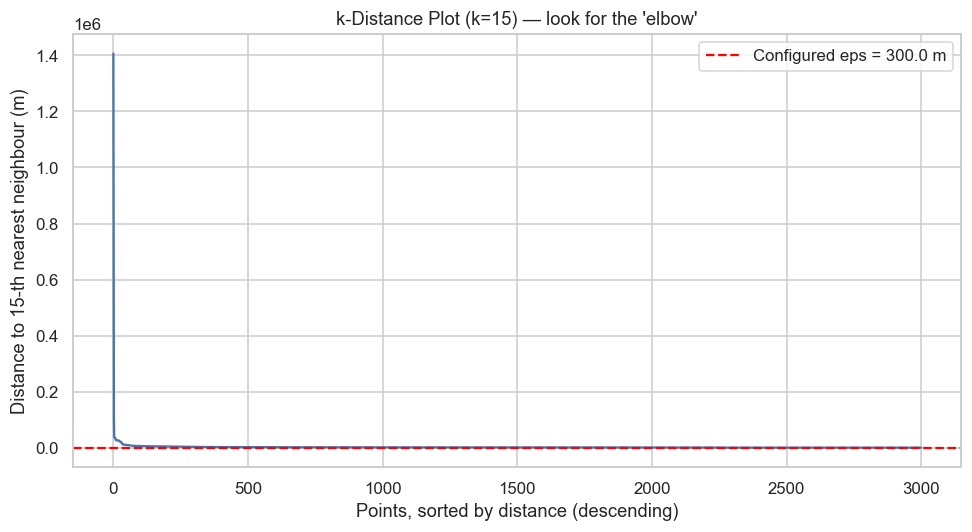

In [6]:
# k-distance elbow plot for a candidate min_samples
K = config.DBSCAN_MIN_SAMPLES
sample_for_kdist = cell_df.sample(n=min(3000, len(cell_df)), random_state=config.RANDOM_SEED)
k_distances = clustering.k_distance_plot_data(sample_for_kdist, k=K)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(k_distances)
ax.set_title(f"k-Distance Plot (k={K}) — look for the 'elbow'")
ax.set_xlabel("Points, sorted by distance (descending)")
ax.set_ylabel(f"Distance to {K}-th nearest neighbour (m)")
ax.axhline(config.DBSCAN_EPS_METERS, color="red", linestyle="--",
           label=f"Configured eps = {config.DBSCAN_EPS_METERS} m")
ax.legend()
fig.tight_layout()
fig.savefig(config.FIGURES_DIR / "07_dbscan_k_distance_elbow.png")
plt.show()


In [7]:
# Parameter comparison grid — evidence for the eps/min_samples choice
param_comparison = clustering.compare_dbscan_parameters(
    cell_df.sample(n=min(5000, len(cell_df)), random_state=config.RANDOM_SEED)
)
param_comparison


,eps_meters,min_samples,n_clusters,n_noise_points,pct_noise
0,150.0,5,137,2755,55.10
1,150.0,10,66,3234,64.68
2,150.0,15,48,3448,68.96
3,150.0,25,32,3747,74.94
4,300.0,5,200,1764,35.28
5,300.0,10,90,2808,56.16
6,300.0,15,52,3313,66.26
7,300.0,25,32,3707,74.14
8,500.0,5,122,848,16.96
9,500.0,10,107,1639,32.78


In [8]:
param_comparison.to_csv(config.TABLES_DIR / "dbscan_parameter_comparison.csv", index=False)

clustered_df = clustering.run_dbscan(
    cell_df, eps_meters=config.DBSCAN_EPS_METERS, min_samples=config.DBSCAN_MIN_SAMPLES
)
cluster_summary_df = clustering.cluster_summary(clustered_df)

n_clusters = (cluster_summary_df["cluster_id"] != -1).sum()
n_noise = int(cluster_summary_df.loc[cluster_summary_df["cluster_id"] == -1, "n_points"].sum()) \
    if (-1 in cluster_summary_df["cluster_id"].values) else 0

print(f"eps = {config.DBSCAN_EPS_METERS} m, min_samples = {config.DBSCAN_MIN_SAMPLES}")
print(f"Clusters found: {n_clusters}")
print(f"Noise points: {n_noise:,} ({100 * n_noise / len(clustered_df):.1f}% of points)")
cluster_summary_df


eps = 300.0 m, min_samples = 15
Clusters found: 237
Noise points: 7,586 (6.5% of points)


,cluster_id,n_points,center_lat,center_lon,is_noise
0,0,69538,39.938308,116.401149,False
1,-1,7586,40.016313,116.500179,True
2,88,1409,39.921224,116.164884,False
3,147,1358,40.063125,116.139841,False
4,21,1290,40.021781,116.263353,False
...,...,...,...,...,...
233,53,14,39.906165,116.230799,False
234,222,12,39.996598,116.479908,False
235,77,10,40.007889,116.392919,False
236,198,10,40.006583,116.336304,False


In [9]:
cluster_summary_df.to_csv(config.TABLES_DIR / "cluster_summary.csv", index=False)
clustered_df.to_csv(config.PROCESSED_DATA_DIR / "clustered_sample.csv", index=False)
print("Saved cluster summary and clustered points.")


Saved cluster summary and clustered points.


## Part 7 — Spatial Hotspots

Cluster sizes, density visualization, and an interactive hotspot map.

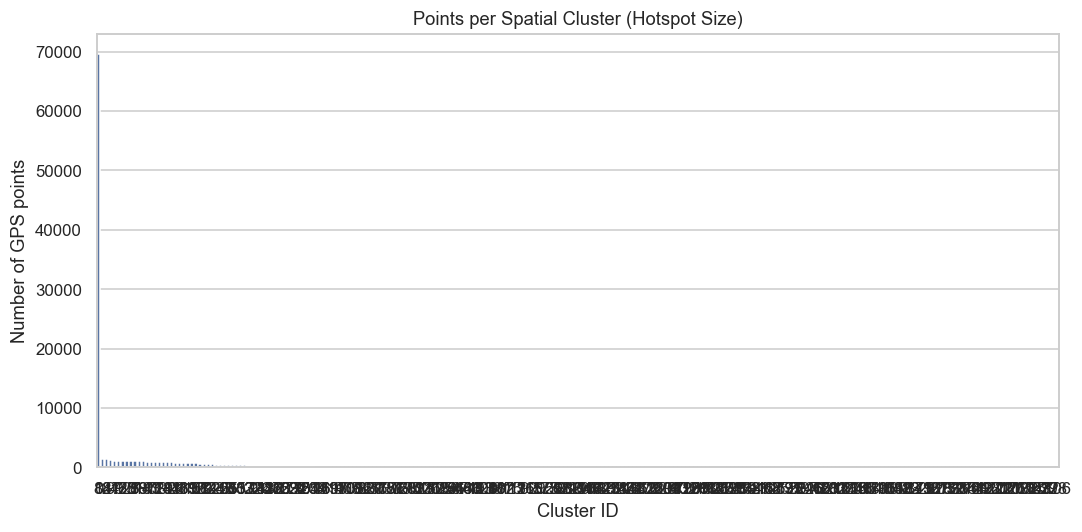

In [10]:
# Cluster size bar chart (excluding noise for readability)
non_noise = cluster_summary_df[cluster_summary_df["cluster_id"] != -1].sort_values("n_points", ascending=False)

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=non_noise, x="cluster_id", y="n_points", order=non_noise["cluster_id"], ax=ax)
ax.set_title("Points per Spatial Cluster (Hotspot Size)")
ax.set_xlabel("Cluster ID")
ax.set_ylabel("Number of GPS points")
fig.tight_layout()
fig.savefig(config.FIGURES_DIR / "08_cluster_sizes.png")
plt.show()


In [11]:
# Density heatmap (all points, not just cluster centers)
center_lat = clustered_df[COL_LAT].median()
center_lon = clustered_df[COL_LON].median()

heat_sample = clustered_df.sample(n=min(5000, len(clustered_df)), random_state=config.RANDOM_SEED)
heat_map = folium.Map(location=[center_lat, center_lon], zoom_start=11, tiles="cartodbpositron")
HeatMap(heat_sample[[COL_LAT, COL_LON]].values.tolist(), radius=12).add_to(heat_map)

heat_map_path = config.MAPS_DIR / "activity_heatmap.html"
heat_map.save(str(heat_map_path))
print(f"Saved activity heatmap to: {heat_map_path}")
heat_map


Saved activity heatmap to: C:\Users\user\Downloads\urban-taxi-mobility\urban-taxi-mobility\outputs\maps\activity_heatmap.html


In [12]:
# Interactive hotspot cluster map: cluster centers sized by point count, noise shown separately
cluster_map = folium.Map(location=[center_lat, center_lon], zoom_start=11, tiles="cartodbpositron")

palette = ["#e6194b", "#3cb44b", "#4363d8", "#f58231", "#911eb4", "#46f0f0",
           "#f032e6", "#bcf60c", "#fabebe", "#008080"]

for _, row in non_noise.iterrows():
    folium.CircleMarker(
        location=[row["center_lat"], row["center_lon"]],
        radius=6 + 14 * (row["n_points"] / non_noise["n_points"].max()),
        color=palette[int(row["cluster_id"]) % len(palette)],
        fill=True,
        fill_opacity=0.6,
        weight=1,
        tooltip=f"Cluster {int(row['cluster_id'])}: {row['n_points']:,} points",
    ).add_to(cluster_map)

# Show a sample of noise points in grey for context
noise_points = clustered_df[clustered_df["cluster_id"] == -1].sample(
    n=min(500, (clustered_df["cluster_id"] == -1).sum()), random_state=config.RANDOM_SEED
) if (clustered_df["cluster_id"] == -1).any() else clustered_df.iloc[0:0]

for _, row in noise_points.iterrows():
    folium.CircleMarker(
        location=[row[COL_LAT], row[COL_LON]],
        radius=1.5, color="#999999", fill=True, fill_opacity=0.4, weight=0,
    ).add_to(cluster_map)

cluster_map_path = config.MAPS_DIR / "hotspot_clusters.html"
cluster_map.save(str(cluster_map_path))
print(f"Saved hotspot cluster map to: {cluster_map_path}")
cluster_map


Saved hotspot cluster map to: C:\Users\user\Downloads\urban-taxi-mobility\urban-taxi-mobility\outputs\maps\hotspot_clusters.html


## Part 8 — Temporal Analysis

Activity by hour, named time-of-day segment, and weekday vs weekend.

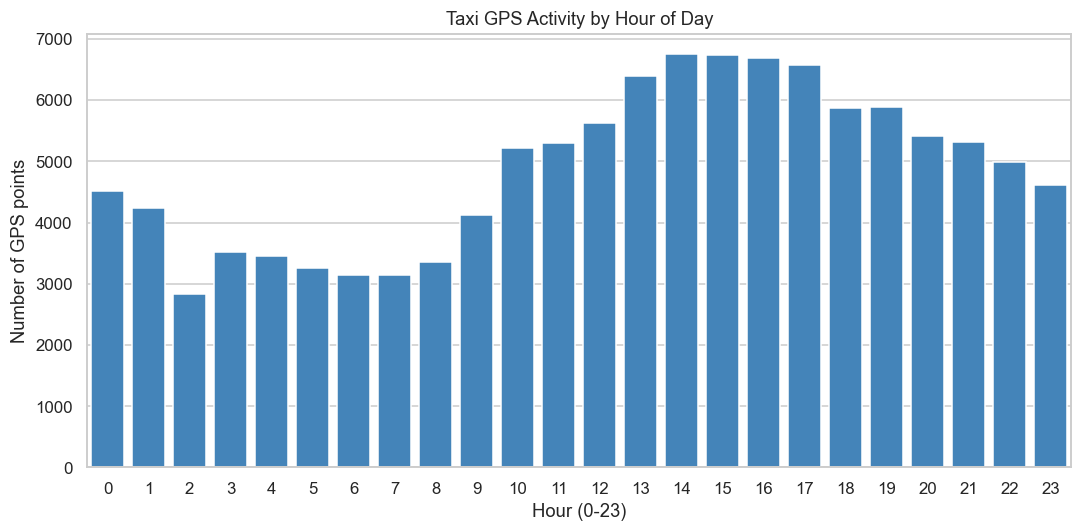

In [13]:
labeled_df = add_temporal_labels(clustered_df)

hourly = temporal.activity_by_hour(labeled_df)
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=hourly, x="hour", y="n_points", color="#3186cc", ax=ax)
ax.set_title("Taxi GPS Activity by Hour of Day")
ax.set_xlabel("Hour (0-23)")
ax.set_ylabel("Number of GPS points")
fig.tight_layout()
fig.savefig(config.FIGURES_DIR / "09_hourly_activity.png")
plt.show()


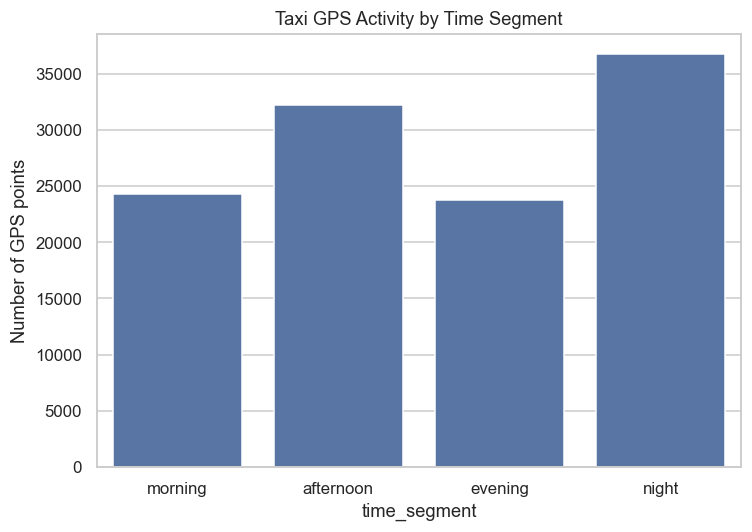

,time_segment,n_points,n_active_taxis
0,morning,24287,92
1,afternoon,32193,99
2,evening,23730,94
3,night,36703,96


In [14]:
segment_summary = temporal.activity_by_segment(labeled_df)
fig, ax = plt.subplots(figsize=(7, 5))
sns.barplot(data=segment_summary, x="time_segment", y="n_points",
            order=["morning", "afternoon", "evening", "night"], ax=ax)
ax.set_title("Taxi GPS Activity by Time Segment")
ax.set_ylabel("Number of GPS points")
fig.tight_layout()
fig.savefig(config.FIGURES_DIR / "10_segment_activity.png")
plt.show()

segment_summary


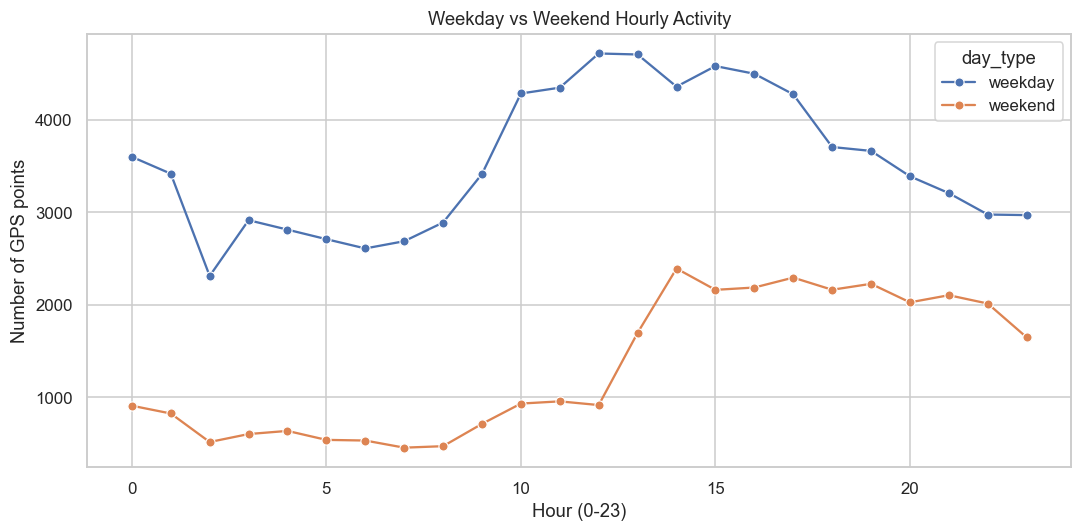

,day_type,n_points,n_active_taxis
0,weekday,84985,96
1,weekend,31928,95


In [15]:
day_type_summary = temporal.activity_by_day_type(labeled_df)
hourly_by_day_type = temporal.activity_by_hour_and_day_type(labeled_df)

fig, ax = plt.subplots(figsize=(10, 5))
sns.lineplot(data=hourly_by_day_type, x="hour", y="n_points", hue="day_type", marker="o", ax=ax)
ax.set_title("Weekday vs Weekend Hourly Activity")
ax.set_xlabel("Hour (0-23)")
ax.set_ylabel("Number of GPS points")
fig.tight_layout()
fig.savefig(config.FIGURES_DIR / "11_weekday_weekend_hourly.png")
plt.show()

day_type_summary


In [16]:
segment_summary.to_csv(config.TABLES_DIR / "activity_by_segment.csv", index=False)
day_type_summary.to_csv(config.TABLES_DIR / "activity_by_day_type.csv", index=False)
hourly.to_csv(config.TABLES_DIR / "activity_by_hour.csv", index=False)
labeled_df.to_csv(config.PROCESSED_DATA_DIR / "labeled_sample.csv", index=False)
print("Saved temporal analysis tables and the fully-labeled sample "
      "(cells + clusters + temporal labels) for use in notebook 03.")


Saved temporal analysis tables and the fully-labeled sample (cells + clusters + temporal labels) for use in notebook 03.


## Notebook 02 Summary

Produced from your actual data:
- A configurable spatial grid with occupied-cell summary
  (`outputs/tables/spatial_grid_summary.csv`)
- An evidence-based DBSCAN parameter choice (k-distance elbow +
  parameter comparison grid) and the resulting clusters
  (`outputs/tables/cluster_summary.csv`, `data/processed/clustered_sample.csv`)
- An activity heatmap and an interactive hotspot cluster map
  (`outputs/maps/`)
- Hourly / segment / weekday-vs-weekend temporal activity tables and charts
- `data/processed/labeled_sample.csv` — cells + clusters + temporal labels
  combined, ready for `03_sequential_mining.ipynb`

**Next:** `03_sequential_mining.ipynb` — sequence building, PrefixSpan
mining, and the sequential + spatial integration (mobility corridors).